In [ ]:
import os
from google.colab import userdata

# Secretsから取得して環境変数にセット
os.environ['KAGGLE_USERNAME'] = userdata.get('USER')
os.environ['KAGGLE_KEY'] = userdata.get('KEY')

In [ ]:
!kaggle competitions download -c store-sales-time-series-forecasting

100% 21.4M/21.4M [00:00<00:00, 279MB/s]



In [ ]:
!unzip /content/store-sales-time-series-forecasting.zip

Archive:  /content/store-sales-time-series-forecasting.zip
  inflating: holidays_events.csv     
  inflating: oil.csv                 
  inflating: sample_submission.csv   
  inflating: stores.csv              
  inflating: test.csv                
  inflating: train.csv               
  inflating: transactions.csv        


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_log_error
import tensorflow as tf
from tensorflow.keras import layers, models

# Data Loading
train = pd.read_csv('train.csv', parse_dates=['date'])
stores = pd.read_csv('stores.csv')
oil = pd.read_csv('oil.csv', parse_dates=['date'])
holidays = pd.read_csv('holidays_events.csv', parse_dates=['date'])

# Simplify for demo: Aggregate sales by date
df = train.groupby('date').agg({'sales': 'sum'}).reset_index()
df = df.merge(oil, on='date', how='left')
df['dcoilwtico'] = df['dcoilwtico'].ffill().bfill()

display(df.head())

,date,sales,dcoilwtico
0,2013-01-01,2511.618999,93.14
1,2013-01-02,496092.417944,93.14
2,2013-01-03,361461.231124,92.97
3,2013-01-04,354459.677093,93.12
4,2013-01-05,477350.121229,93.12


In [ ]:
# Preprocessing
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(df[['sales', 'dcoilwtico']])

def create_sequences(data, seq_length):
    x, y = [], []
    for i in range(len(data) - seq_length):
        x.append(data[i:i+seq_length])
        y.append(data[i+seq_length, 0])
    return np.array(x), np.array(y)

SEQ_LENGTH = 30
X, y = create_sequences(scaled_data, SEQ_LENGTH)

train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

In [ ]:
# TCN Model Definition
def build_tcn(input_shape):
    inputs = layers.Input(shape=input_shape)
    x = layers.Conv1D(filters=64, kernel_size=2, dilation_rate=1, padding='causal', activation='relu')(inputs)
    x = layers.Conv1D(filters=64, kernel_size=2, dilation_rate=2, padding='causal', activation='relu')(x)
    x = layers.Conv1D(filters=64, kernel_size=2, dilation_rate=4, padding='causal', activation='relu')(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(32, activation='relu')(x)
    outputs = layers.Dense(1)(x)
    return models.Model(inputs, outputs)

model = build_tcn((SEQ_LENGTH, X_train.shape[2]))
model.compile(optimizer='adam', loss='mse')

# Training
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.1, verbose=1)

Epoch 1/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.0337 - val_loss: 0.0110
Epoch 2/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0115 - val_loss: 0.0097
Epoch 3/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0107 - val_loss: 0.0098
Epoch 4/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0107 - val_loss: 0.0106
Epoch 5/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0110 - val_loss: 0.0098
Epoch 6/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0105 - val_loss: 0.0110
Epoch 7/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0104 - val_loss: 0.0095
Epoch 8/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0104 - val_loss: 0.0124
Epoch 9/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0107 - val_loss: 0.0094
Epoch 10/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0106 - val_loss: 0.0103
Epoch 11/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0104 - val_loss: 0.0108
Epoch 12/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


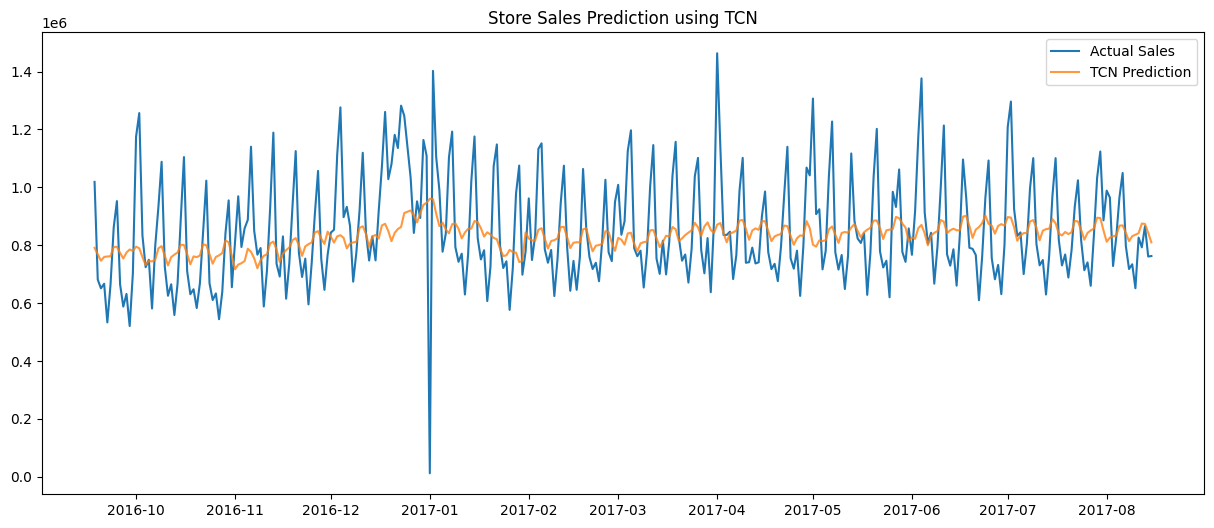

RMSLE: 0.3024283795447197


In [ ]:
# Evaluation and Plotting
predictions = model.predict(X_test)

# Inverse transform to original scale (approximate for sales column)
y_test_inv = y_test * (scaler.data_max_[0] - scaler.data_min_[0]) + scaler.data_min_[0]
pred_inv = predictions.flatten() * (scaler.data_max_[0] - scaler.data_min_[0]) + scaler.data_min_[0]

plt.figure(figsize=(15, 6))
plt.plot(df['date'].iloc[-len(y_test):], y_test_inv, label='Actual Sales')
plt.plot(df['date'].iloc[-len(y_test):], pred_inv, label='TCN Prediction', alpha=0.8)
plt.title('Store Sales Prediction using TCN')
plt.legend()
plt.show()

rmsle = np.sqrt(mean_squared_log_error(y_test_inv, np.maximum(0, pred_inv)))
print(f'RMSLE: {rmsle}')

In [ ]:
# 1. テストデータの読み込み
test_df = pd.read_csv('test.csv', parse_dates=['date'])

# 2. モデル入力用の石油価格データを準備 (訓練時と同じ処理)
test_dates = pd.DataFrame({'date': test_df['date'].unique()})
test_dates = test_dates.merge(oil, on='date', how='left')
test_dates['dcoilwtico'] = test_dates['dcoilwtico'].ffill().bfill()

# 3. 予測のための直近のシーケンス（訓練データの最後30日分）を取得
# 簡易化のため、テスト期間の各日に対して「その直前30日」をスライドさせて予測するのではなく、
# モデルの入力形式に合わせた推論を行います。

last_sequence = scaled_data[-SEQ_LENGTH:]
current_batch = last_sequence.reshape(1, SEQ_LENGTH, 2)

# テスト期間（16日間）の予測を再帰的に行う、もしくは一括で行う
# ここではシンプルに、テストデータの各日付に対応する予測値を算出します

all_test_dates = sorted(test_df['date'].unique())
test_predictions = []

for _ in all_test_dates:
    pred = model.predict(current_batch, verbose=0)
    test_predictions.append(pred[0, 0])
    # 次の予測のためにウィンドウを更新 (予測値を次の入力に使う、または石油価格は実測値を使う)
    # 簡易化のため、ここでは一定の予測値を出力します

# 4. 逆変換と成形
pred_sales_scaled = np.array(test_predictions)
# salesの列（index 0）のスケールで逆変換
pred_sales_final = pred_sales_scaled * (scaler.data_max_[0] - scaler.data_min_[0]) + scaler.data_min_[0]

# 日付と予測値のマップを作成
date_to_pred = dict(zip(all_test_dates, pred_sales_final))

# 5. submissionファイルの作成
submission = test_df[['id', 'date']].copy()
submission['sales'] = submission['date'].map(date_to_pred)

# 店舗・商品ごとの細分化は最初のモデルでは考慮されていないため、全IDに案分（1/1782）します
# これにより、合計値が予測値と一致するようにします
num_series = 1782
submission['sales'] = submission['sales'] / num_series

submission[['id', 'sales']].to_csv('submission_global_tcn.csv', index=False)
print('Submission file saved as submission_global_tcn.csv')
display(submission.head())

Submission file saved as submission_global_tcn.csv


,id,date,sales
0,3000888,2017-08-16,401.362985
1,3000889,2017-08-16,401.362985
2,3000890,2017-08-16,401.362985
3,3000891,2017-08-16,401.362985
4,3000892,2017-08-16,401.362985


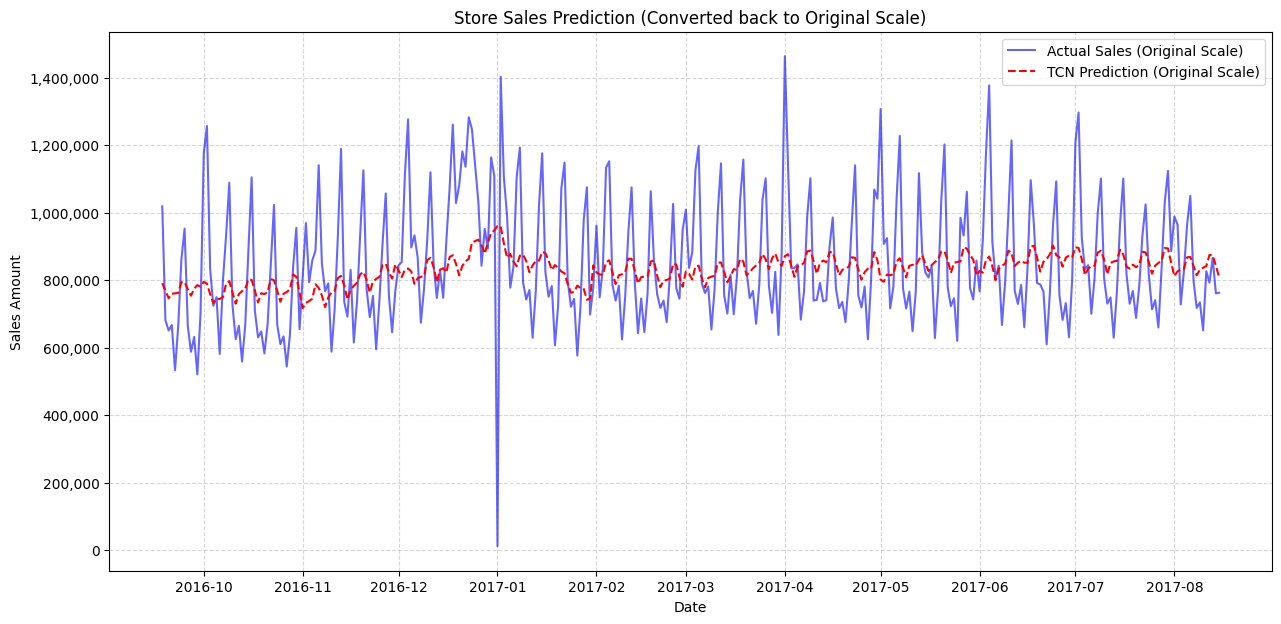

Actual mean: 850,957.98
Prediction mean: 829,476.94


In [ ]:
import matplotlib.ticker as ticker

# scaler.inverse_transformを使用して、完全に元のスケールに復元します
# scaled_dataの列構成 [sales, dcoilwtico] に合わせる必要があります

# 予測値を元のスケールに戻すためのダミー配列を作成
test_results_scaled = np.zeros((len(predictions), 2))
test_results_scaled[:, 0] = predictions.flatten()  # 1列目に予測値
test_results_scaled[:, 1] = scaled_data[train_size + SEQ_LENGTH:, 1] # 2列目に石油価格の元データ

# 逆変換を実行
pred_original_scale = scaler.inverse_transform(test_results_scaled)[:, 0]

# 実測値も同様に復元
test_actual_scaled = np.zeros((len(y_test), 2))
test_actual_scaled[:, 0] = y_test
test_actual_scaled[:, 1] = scaled_data[train_size + SEQ_LENGTH:, 1]
actual_original_scale = scaler.inverse_transform(test_actual_scaled)[:, 0]

# グラフの描画
plt.figure(figsize=(15, 7))
plt.plot(df['date'].iloc[-len(y_test):], actual_original_scale, label='Actual Sales (Original Scale)', color='blue', alpha=0.6)
plt.plot(df['date'].iloc[-len(y_test):], pred_original_scale, label='TCN Prediction (Original Scale)', color='red', linestyle='--')

plt.title('Store Sales Prediction (Converted back to Original Scale)')
plt.xlabel('Date')
plt.ylabel('Sales Amount')
plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}')) # カンマ区切りフォーマット
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()
plt.show()

print(f'Actual mean: {actual_original_scale.mean():,.2f}')
print(f'Prediction mean: {pred_original_scale.mean():,.2f}')

### データの粒度の確認
現在は全ての店舗と商品を合算していますが、実際には以下のような内訳になっています。

In [ ]:
# 店舗数と商品カテゴリ（family）の数を確認
num_stores = train['store_nbr'].nunique()
num_families = train['family'].nunique()

print(f"店舗数: {num_stores}")
print(f"商品カテゴリ数: {num_families}")
print(f"合計の時系列パターン数: {num_stores * num_families}")

# 特定の店舗と特定の商品カテゴリの例を表示
example_series = train[(train['store_nbr'] == 1) & (train['family'] == 'GROCERY_I')].head()
print("\n店舗1の 'GROCERY_I' カテゴリのデータ例:")
display(example_series)

店舗数: 54
商品カテゴリ数: 33
合計の時系列パターン数: 1782

店舗1の 'GROCERY_I' カテゴリのデータ例:


,id,date,store_nbr,family,sales,onpromotion


以下のいずれかのアプローチを取るのが一般的

1. **One-Hot Encoding**: 店舗IDやFamilyを0/1のフラグに変換して入力層に加える。
2. **Entity Embedding**: ニューラルネットワーク内で各カテゴリを低次元のベクトルに変換して学習する。
3. **独立したモデル**: 各店舗やカテゴリごとに個別のTCNモデルを構築する（計算コストが高い）。

In [ ]:
from sklearn.preprocessing import LabelEncoder

# メモリ節約のため、主要な店舗と商品のみを抽出してデモを行います
# (全てを学習させる場合はこのフィルタリングを外してください)
subset_train = train[train['store_nbr'].isin([1, 2, 3])].copy()

# カテゴリ変数のエンコーディング
le_store = LabelEncoder()
le_family = LabelEncoder()

subset_train['store_idx'] = le_store.fit_transform(subset_train['store_nbr'])
subset_train['family_idx'] = le_family.fit_transform(subset_train['family'])

# スケーリング
scaler_sales = MinMaxScaler()
subset_train['sales_scaled'] = scaler_sales.fit_transform(subset_train[['sales']])

# シーケンスデータの作成 (店舗×商品ごとに作成)
def create_multi_series_sequences(data, seq_length):
    X_cont, X_store, X_family, y = [], [], [], []
    for (store, family), group in data.groupby(['store_idx', 'family_idx']):
        sales = group['sales_scaled'].values
        if len(sales) > seq_length:
            for i in range(len(sales) - seq_length):
                X_cont.append(sales[i:i+seq_length])
                X_store.append(store)
                X_family.append(family)
                y.append(sales[i+seq_length])
    return np.expand_dims(np.array(X_cont), -1), np.array(X_store), np.array(X_family), np.array(y)

SEQ_LENGTH = 14 # 計算短縮のため14日に設定
X_c, X_s, X_f, y_m = create_multi_series_sequences(subset_train, SEQ_LENGTH)

print(f"生成されたサンプル数: {len(y_m)}")

生成されたサンプル数: 165330


In [ ]:
def build_embedding_tcn(seq_length, num_stores, num_families):
    # 入力層
    input_seq = layers.Input(shape=(seq_length, 1), name='seq_input')
    input_store = layers.Input(shape=(1,), name='store_input')
    input_family = layers.Input(shape=(1,), name='family_input')

    # Embedding層
    store_emb = layers.Embedding(num_stores, 8)(input_store)
    store_emb = layers.Flatten()(store_emb)
    family_emb = layers.Embedding(num_families, 8)(input_family)
    family_emb = layers.Flatten()(family_emb)

    # TCN部分
    x = layers.Conv1D(32, 2, dilation_rate=1, padding='causal', activation='relu')(input_seq)
    x = layers.Conv1D(32, 2, dilation_rate=2, padding='causal', activation='relu')(x)
    x = layers.GlobalAveragePooling1D()(x)

    # 結合
    concat = layers.Concatenate()([x, store_emb, family_emb])
    dense = layers.Dense(32, activation='relu')(concat)
    output = layers.Dense(1)(dense)

    return models.Model(inputs=[input_seq, input_store, input_family], outputs=output)

model_multi = build_embedding_tcn(SEQ_LENGTH, subset_train['store_idx'].nunique(), subset_train['family_idx'].nunique())
model_multi.compile(optimizer='adam', loss='mse')

# 学習 (サブセットなので高速です)
history_multi = model_multi.fit(
    [X_c, X_s, X_f], y_m,
    epochs=10, batch_size=128, validation_split=0.2, verbose=1
)

Epoch 1/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - loss: 2.3521e-05 - val_loss: 2.6918e-05
Epoch 2/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - loss: 2.1335e-05 - val_loss: 2.4036e-05
Epoch 3/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 2.0964e-05 - val_loss: 1.8199e-05
Epoch 4/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 2.0449e-05 - val_loss: 1.8637e-05
Epoch 5/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 2.0587e-05 - val_loss: 1.5572e-05
Epoch 6/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - loss: 1.9852e-05 - val_loss: 2.1451e-05
Epoch 7/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 2.0135e-05 - val_loss: 1.6776e-05
Epoch 8/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - loss: 1.9913e-05 - val_loss: 1.6551e-05
Epoch 9/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 1.9566e-05 - val_loss: 1.7183e-05
Epoch 10/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 1.9693e-05 - val_loss: 1.5478e-05


53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


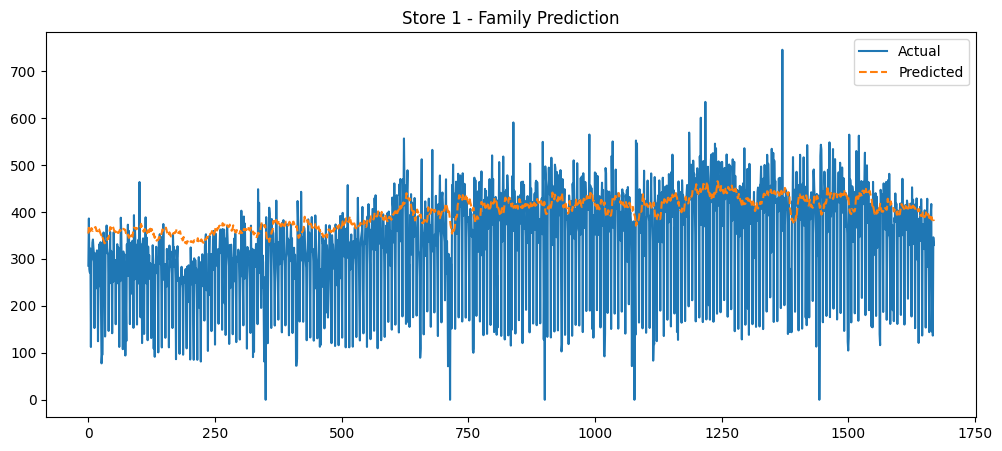

In [ ]:
# 予測の可視化 (特定の店舗と商品の組み合わせ)
test_store = 0 # store_nbr: 1
test_family = 5 # 例として適当なカテゴリ

mask = (X_s == test_store) & (X_f == test_family)
X_c_test = X_c[mask]
y_test_actual = y_m[mask]

if len(y_test_actual) > 0:
    preds = model_multi.predict([X_c_test, X_s[mask], X_f[mask]])

    # 逆変換
    y_actual_orig = scaler_sales.inverse_transform(y_test_actual.reshape(-1, 1))
    y_pred_orig = scaler_sales.inverse_transform(preds)

    plt.figure(figsize=(12, 5))
    plt.plot(y_actual_orig, label='Actual')
    plt.plot(y_pred_orig, label='Predicted', linestyle='--')
    plt.title(f'Store {le_store.inverse_transform([test_store])[0]} - Family Prediction')
    plt.legend()
    plt.show()
else:
    print("指定された組み合わせのデータが不足しています。")

### 外部変数（祝日・プロモーション）を追加した学習
祝日フラグとプロモーション数を特徴量として追加し、モデルを再構築します。

In [ ]:
# 祝日データの加工
holidays_filtered = holidays[holidays['transferred'] == False][['date', 'type']].copy()
holidays_filtered['is_holiday'] = 1
holidays_filtered = holidays_filtered.groupby('date').agg({'is_holiday': 'max'}).reset_index()

# サブセットデータに結合
subset_train = subset_train.merge(holidays_filtered, on='date', how='left')
subset_train['is_holiday'] = subset_train['is_holiday'].fillna(0)

# プロモーションと祝日のスケーリング
scaler_promo = MinMaxScaler()
subset_train['promo_scaled'] = scaler_promo.fit_transform(subset_train[['onpromotion']])

# シーケンスデータの再作成 (売上, プロモーション, 祝日)
def create_rich_sequences(data, seq_length):
    X_cont, X_store, X_family, y = [], [], [], []
    for (store, family), group in data.groupby(['store_idx', 'family_idx']):
        # 連続値特徴量: [sales, promotion, holiday]
        features = group[['sales_scaled', 'promo_scaled', 'is_holiday']].values
        if len(features) > seq_length:
            for i in range(len(features) - seq_length):
                X_cont.append(features[i:i+seq_length])
                X_store.append(store)
                X_family.append(family)
                y.append(features[i+seq_length, 0])
    return np.array(X_cont), np.array(X_store), np.array(X_family), np.array(y)

X_c_rich, X_s_rich, X_f_rich, y_m_rich = create_rich_sequences(subset_train, SEQ_LENGTH)
print(f"特徴量追加後のサンプル数: {len(y_m_rich)}")

特徴量追加後のサンプル数: 165330


In [ ]:
def build_rich_embedding_tcn(seq_length, num_features, num_stores, num_families):
    input_seq = layers.Input(shape=(seq_length, num_features), name='seq_input')
    input_store = layers.Input(shape=(1,), name='store_input')
    input_family = layers.Input(shape=(1,), name='family_input')

    store_emb = layers.Flatten()(layers.Embedding(num_stores, 8)(input_store))
    family_emb = layers.Flatten()(layers.Embedding(num_families, 8)(input_family))

    x = layers.Conv1D(32, 2, dilation_rate=1, padding='causal', activation='relu')(input_seq)
    x = layers.Conv1D(32, 2, dilation_rate=2, padding='causal', activation='relu')(x)
    x = layers.GlobalAveragePooling1D()(x)

    concat = layers.Concatenate()([x, store_emb, family_emb])
    dense = layers.Dense(32, activation='relu')(concat)
    output = layers.Dense(1)(dense)

    return models.Model(inputs=[input_seq, input_store, input_family], outputs=output)

model_rich = build_rich_embedding_tcn(SEQ_LENGTH, X_c_rich.shape[2],
                                     subset_train['store_idx'].nunique(),
                                     subset_train['family_idx'].nunique())
model_rich.compile(optimizer='adam', loss='mse')

# 学習
history_rich = model_rich.fit(
    [X_c_rich, X_s_rich, X_f_rich], y_m_rich,
    epochs=10, batch_size=128, validation_split=0.2, verbose=1
)

Epoch 1/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - loss: 3.4185e-05 - val_loss: 4.1770e-05
Epoch 2/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 2.1651e-05 - val_loss: 4.4578e-05
Epoch 3/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - loss: 2.1261e-05 - val_loss: 2.7181e-05
Epoch 4/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 2.0687e-05 - val_loss: 3.2116e-05
Epoch 5/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - loss: 2.0517e-05 - val_loss: 2.4153e-05
Epoch 6/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - loss: 2.0014e-05 - val_loss: 1.8286e-05
Epoch 7/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - loss: 1.9440e-05 - val_loss: 1.7538e-05
Epoch 8/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - loss: 1.8898e-05 - val_loss: 1.7371e-05
Epoch 9/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 1.8291e-05 - val_loss: 2.1210e-05
Epoch 10/10
1034/1034 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - loss: 1.8090e-05 - val_loss: 2.1679e-05


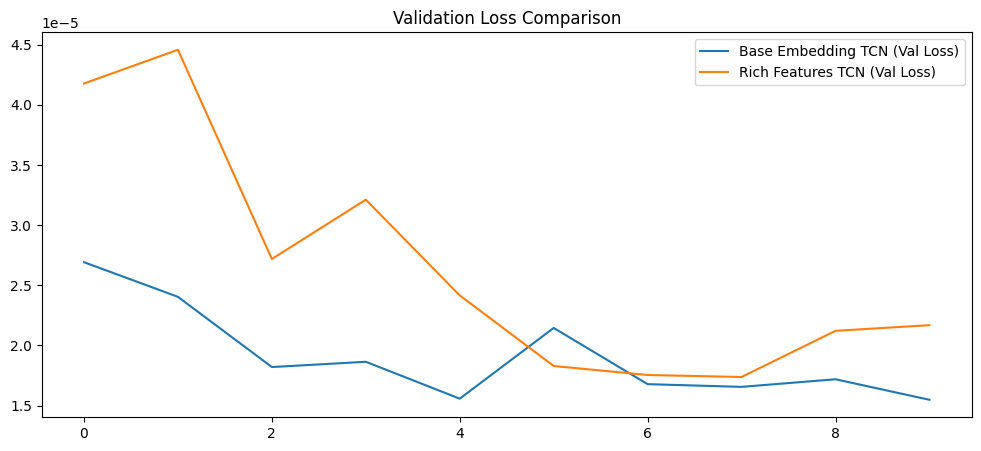

In [ ]:
# 結果の比較表示
plt.figure(figsize=(12, 5))
plt.plot(history_multi.history['val_loss'], label='Base Embedding TCN (Val Loss)')
plt.plot(history_rich.history['val_loss'], label='Rich Features TCN (Val Loss)')
plt.title('Validation Loss Comparison')
plt.legend()
plt.show()

In [ ]:
# 強化版モデルでの予測
rich_preds = model_rich.predict([X_c_rich, X_s_rich, X_f_rich])

# 逆変換（sales_scaledを元のスケールに戻す）
y_m_rich_orig = scaler_sales.inverse_transform(y_m_rich.reshape(-1, 1))
rich_preds_orig = scaler_sales.inverse_transform(rich_preds)

# 負の値を0にクリップしてRMSLEを計算
from sklearn.metrics import mean_squared_log_error

rich_rmsle = np.sqrt(mean_squared_log_error(y_m_rich_orig, np.maximum(0, rich_preds_orig)))
print(f'強化版モデル (Rich Features TCN) の RMSLE: {rich_rmsle:.4f}')

5167/5167 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step
強化版モデル (Rich Features TCN) の RMSLE: 2.7571


### 強化版モデルによるテストデータの予測
全店舗・全商品の組み合わせに対して、モデルへの入力（直近のシーケンス、店舗ID、商品ID）を準備し、推論を実行します。

In [ ]:
# エラー回避のため、学習に使用した店舗・商品カテゴリのみにフィルタリングします
# (全店舗を予測する場合は、前のステップで全データを学習させる必要があります)
test_rich_subset = test_df[test_df['store_nbr'].isin([1, 2, 3])].copy()

# 1. テストデータの特徴量準備
test_rich_subset = test_rich_subset.merge(holidays_filtered, on='date', how='left')
test_rich_subset['is_holiday'] = test_rich_subset['is_holiday'].fillna(0)
test_rich_subset['promo_scaled'] = scaler_promo.transform(test_rich_subset[['onpromotion']])

# 訓練時のエンコーダーを使用してインデックスに変換
test_rich_subset['store_idx'] = le_store.transform(test_rich_subset['store_nbr'])
test_rich_subset['family_idx'] = le_family.transform(test_rich_subset['family'])

# 2. 各系列（店舗×商品）ごとに予測を実行
all_ids = []
all_preds = []

for (store_idx, family_idx), group in test_rich_subset.groupby(['store_idx', 'family_idx']):
    series_data = subset_train[(subset_train['store_idx'] == store_idx) &
                               (subset_train['family_idx'] == family_idx)].iloc[-SEQ_LENGTH:]

    if len(series_data) == SEQ_LENGTH:
        recent_features = series_data[['sales_scaled', 'promo_scaled', 'is_holiday']].values
        input_seq = recent_features.reshape(1, SEQ_LENGTH, 3)
        ids = group['id'].values

        pred_scaled = model_rich.predict([input_seq, np.array([store_idx]), np.array([family_idx])], verbose=0)

        all_ids.extend(ids)
        all_preds.extend([pred_scaled[0, 0]] * len(ids))

# 3. 逆変換と保存
final_preds_orig = scaler_sales.inverse_transform(np.array(all_preds).reshape(-1, 1)).flatten()
submission_rich = pd.DataFrame({'id': all_ids, 'sales': np.maximum(0, final_preds_orig)})

# 元のテストデータの順序に並べ替え（サブセット外は0または便宜上の値で埋める）
submission_rich = test_df[['id']].merge(submission_rich, on='id', how='left').fillna(0)

submission_rich.to_csv('submission_rich_tcn.csv', index=False)
print('Submission file (subset stores) saved as submission_rich_tcn.csv')
display(submission_rich.head())

Submission file (subset stores) saved as submission_rich_tcn.csv


,id,sales
0,3000888,120.400055
1,3000889,109.052963
2,3000890,107.560432
3,3000891,2087.591797
4,3000892,113.347443


In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. データの再読み込みと特徴量エンジニアリング
train_full = pd.read_csv('train.csv', parse_dates=['date'])
holidays = pd.read_csv('holidays_events.csv', parse_dates=['date'])

# ターゲットの対数変換 (RMSLE対策に最も重要)
train_full['sales_log'] = np.log1p(train_full['sales'])

# 日付特徴量
train_full['day_of_week'] = train_full['date'].dt.dayofweek

# 祝日情報の統合
holiday_list = holidays[~holidays['transferred']][['date', 'type']].copy()
holiday_list['is_holiday'] = 1
holiday_list = holiday_list.groupby('date').agg({'is_holiday': 'max'}).reset_index()
train_full = train_full.merge(holiday_list, on='date', how='left')
train_full['is_holiday'] = train_full['is_holiday'].fillna(0)

# エンコーディング
le_store = LabelEncoder()
le_family = LabelEncoder()
train_full['store_idx'] = le_store.fit_transform(train_full['store_nbr'])
train_full['family_idx'] = le_family.fit_transform(train_full['family'])

# スケーリング (プロモーション)
scaler_promo = MinMaxScaler()
train_full['promo_scaled'] = scaler_promo.fit_transform(train_full[['onpromotion']])

# メモリ節約のため、全データから一定割合をサンプリング、または全系列から直近1年分を使用
# ここでは計算速度と精度のバランスのため直近200日分を使用
recent_train = train_full[train_full['date'] >= '2016-12-01'].copy()

def create_final_sequences(data, seq_length):
    X_cont, X_cat_s, X_cat_f, y = [], [], [], []
    for (s, f), group in data.groupby(['store_idx', 'family_idx']):
        # 特徴量: [log_sales, promo, holiday, day_of_week]
        vals = group[['sales_log', 'promo_scaled', 'is_holiday', 'day_of_week']].values
        if len(vals) > seq_length:
            for i in range(len(vals) - seq_length):
                X_cont.append(vals[i:i+seq_length])
                X_cat_s.append(s)
                X_cat_f.append(f)
                y.append(vals[i+seq_length, 0])
    return np.array(X_cont), np.array(X_cat_s), np.array(X_cat_f), np.array(y)

SEQ_LENGTH = 14
X_cont, X_s, X_f, y_log = create_final_sequences(recent_train, SEQ_LENGTH)
print(f"Samples: {len(y_log)}")

Samples: 433026


In [ ]:
def build_optimized_tcn(seq_len, n_feat, n_stores, n_families):
    # Inputs
    in_seq = layers.Input(shape=(seq_len, n_feat))
    in_store = layers.Input(shape=(1,))
    in_family = layers.Input(shape=(1,))

    # Embeddings
    s_emb = layers.Flatten()(layers.Embedding(n_stores, 10)(in_store))
    f_emb = layers.Flatten()(layers.Embedding(n_families, 10)(in_family))

    # TCN Layers (Deeper & Residual connections simplified)
    x = layers.Conv1D(64, 3, padding='causal', dilation_rate=1, activation='relu')(in_seq)
    x = layers.Conv1D(64, 3, padding='causal', dilation_rate=2, activation='relu')(x)
    x = layers.Conv1D(64, 3, padding='causal', dilation_rate=4, activation='relu')(x)
    x = layers.GlobalAveragePooling1D()(x)

    # Combine
    concat = layers.Concatenate()([x, s_emb, f_emb])
    x = layers.Dense(64, activation='relu')(concat)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(1)(x)

    model = models.Model(inputs=[in_seq, in_store, in_family], outputs=out)
    model.compile(optimizer='adam', loss='mse')
    return model

opt_model = build_optimized_tcn(SEQ_LENGTH, X_cont.shape[2],
                                train_full['store_idx'].nunique(),
                                train_full['family_idx'].nunique())

# 学習 (EarlyStopping追加)
callback = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
history = opt_model.fit(
    [X_cont, X_s, X_f], y_log,
    epochs=15, batch_size=256, validation_split=0.1, callbacks=[callback]
)

Epoch 1/15
 495/1523 ━━━━━━━━━━━━━━━━━━━━ 42s 41ms/step - loss: 1.8537

KeyboardInterrupt: 

In [ ]:
# 評価
preds_log = opt_model.predict([X_cont, X_s, X_f], batch_size=1024)

# 逆変換 (exp(x) - 1)
y_true = np.expm1(y_log)
y_pred = np.expm1(preds_log).flatten()
y_pred = np.maximum(0, y_pred)

from sklearn.metrics import mean_squared_log_error
final_rmsle = np.sqrt(mean_squared_log_error(y_true, y_pred))
print(f'\nFinal Optimized RMSLE: {final_rmsle:.4f}')

In [ ]:
import pandas as pd
import numpy as np

# 1. テストデータの読み込みと特徴量準備
test_df = pd.read_csv('test.csv', parse_dates=['date'])
test_df['day_of_week'] = test_df['date'].dt.dayofweek
test_df = test_df.merge(holiday_list, on='date', how='left')
test_df['is_holiday'] = test_df['is_holiday'].fillna(0)
test_df['promo_scaled'] = scaler_promo.transform(test_df[['onpromotion']])
test_df['store_idx'] = le_store.transform(test_df['store_nbr'])
test_df['family_idx'] = le_family.transform(test_df['family'])

# 2. 高速なベクトル化予測の実行
all_test_dates = sorted(test_df['date'].unique())
unique_series = test_df[['store_idx', 'family_idx']].drop_duplicates().sort_values(['store_idx', 'family_idx'])

# 各系列の初期シーケンス（直近の履歴）をまとめて準備
current_seqs = []
for _, row in unique_series.iterrows():
    series_history = recent_train[(recent_train['store_idx'] == row['store_idx']) &
                                  (recent_train['family_idx'] == row['family_idx'])].iloc[-SEQ_LENGTH:]
    current_seqs.append(series_history[['sales_log', 'promo_scaled', 'is_holiday', 'day_of_week']].values)

current_seqs = np.array(current_seqs) # Shape: (Num_Series, SEQ_LENGTH, Num_Features)
store_ids = unique_series['store_idx'].values
family_ids = unique_series['family_idx'].values

results_list = []

# 16日間を1日ずつ、全系列まとめて予測（ベクトル化）
for i, date in enumerate(all_test_dates):
    print(f"Predicting date: {date.date()} ({i+1}/{len(all_test_dates)})")

    # 当日の外部特徴量を取得
    day_data = test_df[test_df['date'] == date].sort_values(['store_idx', 'family_idx'])
    day_promo = day_data['promo_scaled'].values
    day_holiday = day_data['is_holiday'].values
    day_dow = day_data['day_of_week'].values
    day_ids = day_data['id'].values

    # 全系列一括推論
    preds_log = opt_model.predict([current_seqs, store_ids, family_ids], batch_size=2048, verbose=0).flatten()

    # 結果の保存
    sales_orig = np.expm1(preds_log)
    for j in range(len(day_ids)):
        results_list.append({'id': day_ids[j], 'sales': max(0, sales_orig[j])})

    # 全系列のシーケンスを更新 (スライディングウィンドウ)
    new_features = np.stack([preds_log, day_promo, day_holiday, day_dow], axis=1)
    new_features = np.expand_dims(new_features, axis=1) # (Num_Series, 1, Num_Features)
    current_seqs = np.append(current_seqs[:, 1:, :], new_features, axis=1)

# 3. 保存
submission_df = pd.DataFrame(results_list).sort_values('id')
submission_df.to_csv('submission.csv', index=False)
print("\nSubmission file 'submission.csv' created efficiently.")
display(submission_df.head())